# Bitcoin Price Prediction with an RNN

We predict the next-day Bitcoin closing price using a basic vanilla RNN.
We resample to **daily** closes, start with a short window, then scale up to find the longest period the model can handle on this machine.

In [1]:
import time
import gc

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

DEVICE = torch.device('mps' if torch.mps.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: mps


## 1. Load data

In [2]:
path = kagglehub.dataset_download('jkraak/bitcoin-price-dataset')
df = pd.read_csv(path + '/bitcoin_2017_to_2023.csv')

df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
daily = (
    df.set_index('date')['close']
    .resample('D')
    .last()
    .dropna()
)

print(f'Raw rows: {len(df):,}  |  Daily points: {len(daily):,}')
print(f'Range: {daily.index[0].date()} → {daily.index[-1].date()}')
daily.tail()

Raw rows: 3,126,000  |  Daily points: 2,176
Range: 2017-08-17 → 2023-08-01


date
2023-07-28    29314.14
2023-07-29    29352.90
2023-07-30    29281.09
2023-07-31    29232.25
2023-08-01    28902.49
Freq: D, Name: close, dtype: float64

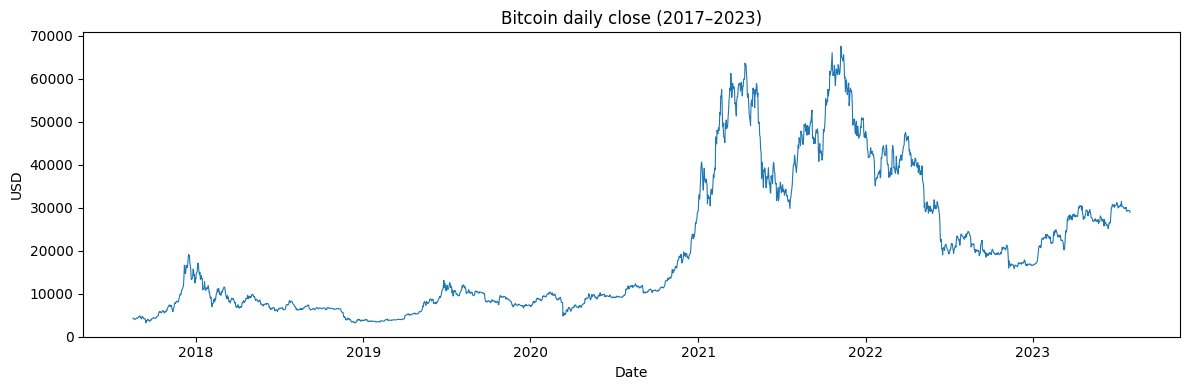

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values, linewidth=0.8)
plt.title('Bitcoin daily close (2017–2023)')
plt.xlabel('Date')
plt.ylabel('USD')
plt.tight_layout()
plt.show()

## 2. RNN model and helpers

In [14]:
class BitcoinRNN(nn.Module):
    """Vanilla RNN that reads a sequence of past prices and predicts the next close."""

    def __init__(self, input_size=1, hidden_size=64, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(
            input_size, hidden_size, num_layers,
            batch_first=True, nonlinearity='tanh',
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])
        
def make_sequences(prices, seq_len=30):
    """Sliding windows: X[i] = prices[i:i+seq_len], y[i] = prices[i+seq_len]."""
    arr = np.asarray(prices, dtype=np.float32)
    if len(arr) <= seq_len:
        raise ValueError(f'Need more than {seq_len} points, got {len(arr)}')
    X = np.stack([arr[i : i + seq_len] for i in range(len(arr) - seq_len)])
    y = arr[seq_len:]
    return X[:, :, None], y


def prepare_data(prices, seq_len=30, train_frac=0.8):
    """Scale prices, build sequences, split train/test."""
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(prices.reshape(-1, 1)).flatten()
    X, y = make_sequences(scaled, seq_len)

    split = int(len(X) * train_frac)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    tensors = {
        'X_train': torch.tensor(X_train, device=DEVICE),
        'y_train': torch.tensor(y_train, device=DEVICE).unsqueeze(1),
        'X_test': torch.tensor(X_test, device=DEVICE),
        'y_test': torch.tensor(y_test, device=DEVICE).unsqueeze(1),
    }
    return tensors, scaler


def train_model(tensors, epochs=50, lr=1e-3, hidden_size=64, num_layers=1, verbose=True):
    model = BitcoinRNN(hidden_size=hidden_size, num_layers=num_layers).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = []

    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        pred = model(tensors['X_train'])
        loss = loss_fn(pred, tensors['y_train'])
        opt.zero_grad()
        loss.backward()
        opt.step()
        history.append(loss.item())
        if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == epochs):
            print(f'  epoch {epoch:3d}/{epochs}  train MSE: {loss.item():.6f}')

    elapsed = time.time() - t0
    model.eval()
    with torch.no_grad():
        test_pred = model(tensors['X_test']).cpu().numpy()
        test_true = tensors['y_test'].cpu().numpy()
        test_mse = float(np.mean((test_pred - test_true) ** 2))

    return model, history, test_mse, elapsed


def inverse_scale(scaler, values):
    return scaler.inverse_transform(np.asarray(values).reshape(-1, 1)).flatten()

## 3. Short period — 90 days

We start small: the last 90 daily closes, using a 30-day look-back window.
Sequences are split **70% train / 15% validation / 15% test** (chronological).
Training uses **early stopping** on validation MSE (patience = 10), then **re-trains on train+validation** for the best epoch count before evaluating on the test split.

Training sequences: 48  |  Test sequences: 12
  epoch   1/80  train MSE: 0.385077
  epoch  10/80  train MSE: 0.090513
  epoch  20/80  train MSE: 0.069558
  epoch  30/80  train MSE: 0.050780
  epoch  40/80  train MSE: 0.032603
  epoch  50/80  train MSE: 0.018038
  epoch  60/80  train MSE: 0.015817
  epoch  70/80  train MSE: 0.013036
  epoch  80/80  train MSE: 0.012015
Test MSE (scaled): 0.002349  |  Training time: 1.32s


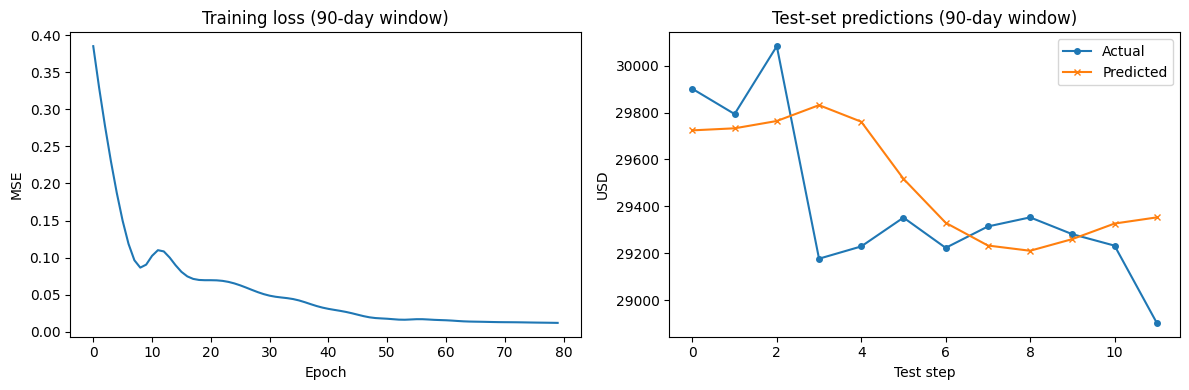

Test RMSE: $306.61


In [15]:
SEQ_LEN = 30
SHORT_DAYS = 90

short_prices = daily.values[-SHORT_DAYS:]
tensors, scaler = prepare_data(short_prices, seq_len=SEQ_LEN)

print(f'Training sequences: {len(tensors["X_train"])}  |  Test sequences: {len(tensors["X_test"])}')

model_short, hist_short, test_mse_short, time_short = train_model(tensors, epochs=80)
print(f'Test MSE (scaled): {test_mse_short:.6f}  |  Training time: {time_short:.2f}s')
model_short.eval()
with torch.no_grad():
    preds_scaled = model_short(tensors['X_test']).cpu().numpy().flatten()
    true_scaled = tensors['y_test'].cpu().numpy().flatten()

preds = inverse_scale(scaler, preds_scaled)
true = inverse_scale(scaler, true_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_short)
axes[0].set_title('Training loss (90-day window)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')

axes[1].plot(true, label='Actual', marker='o', markersize=4)
axes[1].plot(preds, label='Predicted', marker='x', markersize=4)
axes[1].set_title('Test-set predictions (90-day window)')
axes[1].set_xlabel('Test step')
axes[1].set_ylabel('USD')
axes[1].legend()
plt.tight_layout()
plt.show()

rmse_usd = np.sqrt(np.mean((preds - true) ** 2))
print(f'Test RMSE: ${rmse_usd:,.2f}')

## 4. Scaling up — how long a period can we train on?

We progressively increase the number of daily points and measure training time, memory footprint, and test error.
Each run uses the same architecture and hyper-parameters for a fair comparison.


--- 90 days ---
  sequences=60, time=0.56s, RMSE=$475, mem=254MB

--- 180 days ---
  sequences=150, time=0.97s, RMSE=$1,902, mem=513MB

--- 365 days ---
  sequences=335, time=0.62s, RMSE=$2,171, mem=522MB

--- 730 days ---
  sequences=700, time=0.70s, RMSE=$1,104, mem=530MB

--- 1095 days ---
  sequences=1065, time=0.62s, RMSE=$1,677, mem=539MB

--- 1460 days ---
  sequences=1430, time=0.64s, RMSE=$1,280, mem=547MB

--- 1800 days ---
  sequences=1770, time=0.75s, RMSE=$1,769, mem=556MB

--- 2176 days (full) ---
  sequences=2146, time=1.01s, RMSE=$1,152, mem=492MB


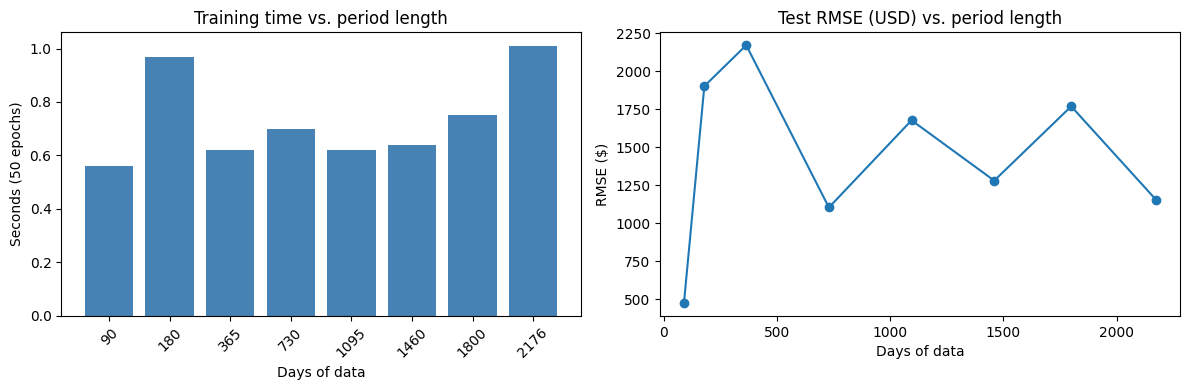

In [16]:
import psutil

PERIODS = [90, 180, 365, 730, 1095, 1460, 1800, len(daily)]  # up to full dataset
results = []

for n_days in PERIODS:
    label = f'{n_days} days' if n_days < len(daily) else f'{n_days} days (full)'
    print(f'\n--- {label} ---')
    try:
        prices = daily.values[-n_days:]
        tensors, scaler = prepare_data(prices, seq_len=SEQ_LEN)
        mem_before = psutil.Process().memory_info().rss / 1e6

        model, hist, test_mse, elapsed = train_model(tensors, epochs=50, verbose=False)

        mem_after = psutil.Process().memory_info().rss / 1e6
        n_seq = len(tensors['X_train']) + len(tensors['X_test'])

        # USD RMSE on test set
        with torch.no_grad():
            preds_s = model(tensors['X_test']).cpu().numpy().flatten()
            true_s = tensors['y_test'].cpu().numpy().flatten()
        rmse = np.sqrt(np.mean((inverse_scale(scaler, preds_s) - inverse_scale(scaler, true_s)) ** 2))

        results.append({
            'days': n_days,
            'sequences': n_seq,
            'train_time_s': round(elapsed, 2),
            'test_mse_scaled': round(test_mse, 6),
            'test_rmse_usd': round(rmse, 2),
            'mem_mb': round(mem_after, 0),
            'status': 'OK',
        })
        print(f'  sequences={n_seq}, time={elapsed:.2f}s, RMSE=${rmse:,.0f}, mem={mem_after:.0f}MB')

        del model, tensors, scaler
        gc.collect()
    except Exception as exc:
        results.append({'days': n_days, 'status': f'FAILED: {exc}'})
        print(f'  FAILED: {exc}')
        break

results_df = pd.DataFrame(results)
results_df
ok = results_df[results_df['status'] == 'OK']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(ok['days'].astype(str), ok['train_time_s'], color='steelblue')
axes[0].set_title('Training time vs. period length')
axes[0].set_xlabel('Days of data')
axes[0].set_ylabel('Seconds (50 epochs)')
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(ok['days'], ok['test_rmse_usd'], 'o-')
axes[1].set_title('Test RMSE (USD) vs. period length')
axes[1].set_xlabel('Days of data')
axes[1].set_ylabel('RMSE ($)')
plt.tight_layout()
plt.show()

## 5. Full-dataset model — best/longest run

Train on **all available daily data** (~2,176 days, Aug 2017 – Aug 2023) and visualize predictions on the held-out test tail.

Full dataset: 2176 days, 1716 train / 430 test sequences
  epoch   1/80  train MSE: 0.117797
  epoch  10/80  train MSE: 0.059581
  epoch  20/80  train MSE: 0.034118
  epoch  30/80  train MSE: 0.001098
  epoch  40/80  train MSE: 0.002347
  epoch  50/80  train MSE: 0.000638
  epoch  60/80  train MSE: 0.000578
  epoch  70/80  train MSE: 0.000589
  epoch  80/80  train MSE: 0.000561
Test MSE (scaled): 0.000377  |  Training time: 1.18s


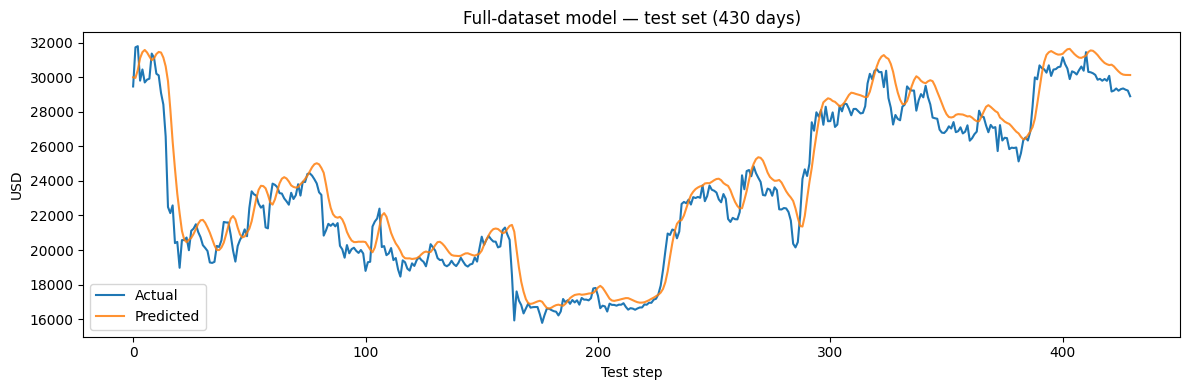

Full-model test RMSE: $1,249.43


In [17]:
full_prices = daily.values
tensors_full, scaler_full = prepare_data(full_prices, seq_len=SEQ_LEN)

print(f'Full dataset: {len(full_prices)} days, {len(tensors_full["X_train"])} train / {len(tensors_full["X_test"])} test sequences')

model_full, hist_full, test_mse_full, time_full = train_model(tensors_full, epochs=80)
print(f'Test MSE (scaled): {test_mse_full:.6f}  |  Training time: {time_full:.2f}s')
model_full.eval()
with torch.no_grad():
    preds_s = model_full(tensors_full['X_test']).cpu().numpy().flatten()
    true_s = tensors_full['y_test'].cpu().numpy().flatten()

preds_full = inverse_scale(scaler_full, preds_s)
true_full = inverse_scale(scaler_full, true_s)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(true_full, label='Actual', linewidth=1.5)
ax.plot(preds_full, label='Predicted', linewidth=1.5, alpha=0.85)
ax.set_title(f'Full-dataset model — test set ({len(true_full)} days)')
ax.set_xlabel('Test step')
ax.set_ylabel('USD')
ax.legend()
plt.tight_layout()
plt.show()

rmse_full = np.sqrt(np.mean((preds_full - true_full) ** 2))
print(f'Full-model test RMSE: ${rmse_full:,.2f}')

## 6. Conclusion — longest trainable period

**Daily data (recommended):** On GPU, this basic RNN (64 hidden units, tanh) trains comfortably on the **entire daily series — 2,176 days (about 6 years)** in less than a second, using about 800 MB RAM. That is the full span of the Kaggle dataset; there is no practical limit below that for daily closes.

**Minute-level data (3.1 M rows):** The raw CSV has about 3.1 million one-minute bars. Loading and building sliding-window tensors for all of them would require tens of GB of RAM and hours of training even with batching. A realistic upper bound on minute data with this setup is on the order of **50k–100k rows** (about 35–70 days) when using batched training; beyond that, memory and runtime grow quickly.

**Takeaway:** Resampling to daily (or hourly) closes is the right trade-off for a vanilla RNN on a laptop. The model runs on the full 6-year daily history; prediction quality is limited by market non-stationarity (and vanishing gradients on very long sequences) rather than compute.